In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.tree import DecisionTreeRegressor

In [5]:
# Memuat dataset dari file CSV
df = pd.read_csv("/content/airlines_flights_data.csv")
df.head()

FileNotFoundError: [Errno 2] No such file or directory: '/content/airlines_flights_data.csv'

In [ ]:
df.duplicated().sum()

In [ ]:
df.describe(include='object')

In [ ]:
df.isnull().sum()

In [ ]:
df.info()

In [ ]:
df.describe(include='object')

**Eksplorasi Data (Exploratory Data Analysis - EDA)**

In [ ]:
# Memeriksa distribusi kolom 'price' (harga)
plt.figure(figsize=(10, 6))
sns.histplot(df['price'], bins=50, kde=True)
plt.title('Distribusi Harga Tiket Pesawat')
plt.xlabel('Harga')
plt.ylabel('Frekuensi')
plt.show()

In [ ]:
# Deteksi Outlier pada Harga Tiket (kategorical)
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['price'])
plt.title('Deteksi Outlier pada Harga Tiket')
plt.xlabel('Harga')
plt.show()

In [ ]:
# Deteksi Outlier pada Durasi Penerbangan (kategorical)
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['duration'])
plt.title('Deteksi Outlier pada Durasi Penerbangan')
plt.xlabel('Durasi (jam)')
plt.show()

In [ ]:
# Visualisasi distribusi data 'airline' (numerikal)
plt.figure(figsize=(15, 6))
sns.countplot(x='airline', data=df)
plt.title('Distribusi Jumlah Penerbangan per Maskapai')
plt.xlabel('Maskapai')
plt.ylabel('Jumlah Penerbangan')
plt.xticks(rotation=45) # Memutar label agar tidak tumpang tindih
plt.show()

In [ ]:
# Visualisasi distribusi data 'class' (numerikal)
plt.figure(figsize=(8, 6))
sns.countplot(x='class', data=df)
plt.title('Distribusi Jumlah Penerbangan per Kelas')
plt.xlabel('Kelas')
plt.ylabel('Jumlah Penerbangan')
plt.show()

In [ ]:
# Analisis hubungan antara kelas penerbangan dan harga
# Berdasarkan visualisasi, harga tiket kelas Bisnis jauh lebih tinggi daripada kelas Ekonomi.
plt.figure(figsize=(8, 6))
sns.boxplot(x='class', y='price', data=df)
plt.title('Harga Berdasarkan Kelas Penerbangan')
plt.xlabel('Kelas Penerbangan')
plt.ylabel('Harga')
plt.show()

In [ ]:
# Analisis hubungan antara maskapai dan harga
plt.figure(figsize=(12, 7))
sns.boxplot(x='airline', y='price', data=df)
plt.title('Harga Berdasarkan Maskapai Penerbangan')
plt.xlabel('Maskapai')
plt.ylabel('Harga')
plt.xticks(rotation=45)
plt.show()

**Data Preprocessing**

In [ ]:
# Data dictionary (punyamu tadi)
data = {
    'index': [1, 2, 3],
    'flight': ['GA123', 'JT456', 'QZ789'],
    'airline': ['Garuda', 'Lion Air', 'AirAsia'],
    'source_city': ['Jakarta', 'Surabaya', 'Bali'],
    'departure_time': ['Morning', 'Evening', 'Afternoon'],
    'stops': ['non-stop', '1 stop', '2 stops'],
    'arrival_time': ['Night', 'Afternoon', 'Morning'],
    'destination_city': ['Singapore', 'Jakarta', 'Kuala Lumpur'],
    'class': ['Economy', 'Business', 'Economy'],
    'duration': [2.5, 1.0, 3.0],
    'days_left': [30, 10, 5],
    'price': [1500000, 2500000, 1200000]
}

# Ubah ke DataFrame
df = pd.DataFrame(data)

# Tampilkan tabel
print(df)


In [ ]:
# Pilih fitur (X) dan target (y)
X = df.drop('price', axis=1)
y = df['price']

# Hapus kolom yang tidak relevan untuk prediksi harga
X = X.drop(['index', 'flight'], axis=1)

# Mengidentifikasi fitur kategorikal dan numerik
categorical_cols = [
    'airline', 'source_city', 'departure_time',
    'stops', 'arrival_time', 'destination_city', 'class'
]
numerical_cols = ['duration', 'days_left']

# Terapkan One-Hot Encoding pada fitur kategorikal
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

print("\nShape data setelah One-Hot Encoding:")
print(X_encoded.shape)
print("\nKolom-kolom setelah preprocessing:")
print(X_encoded.columns)

# Split data menjadi 80% training dan 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,  # fitur setelah preprocessing
    y,          # target (price)
    test_size=0.2,   # 20% untuk test
    random_state=42  # biar hasil konsisten
)


**Machine Learning Modeling dan Evaluasi**

In [ ]:
# Daftar model
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
}

# Simpan hasil evaluasi
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE Train": mean_absolute_error(y_train, pred_train),
        "R2 Train": r2_score(y_train, pred_train),
        "MAE Test": mean_absolute_error(y_test, pred_test),
        "R2 Test": r2_score(y_test, pred_test)
    })

# Hasil ringkas dalam DataFrame
results_df = pd.DataFrame(results).set_index("Model")
results_df


In [ ]:

# Linear Regression
coefs = pd.Series(models["Linear Regression"].coef_, index=X_train.columns).sort_values(ascending=False)
plt.figure(figsize=(8,6))
coefs.head(10).plot(kind="barh")
plt.gca().invert_yaxis()
plt.title("Top 10 Fitur Paling Berpengaruh (Linear Regression)")
plt.xlabel("Koefisien")
plt.show()

In [ ]:
# Decision Tree
importances_tree = models["Decision Tree"].feature_importances_
fi_tree = pd.Series(importances_tree, index=X_train.columns).sort_values(ascending=False)
plt.figure(figsize=(8,6))
fi_tree.head(10).plot(kind="barh")
plt.gca().invert_yaxis()
plt.title("Top 10 Fitur Paling Berpengaruh (Decision Tree)")
plt.xlabel("Importance Score")
plt.show()


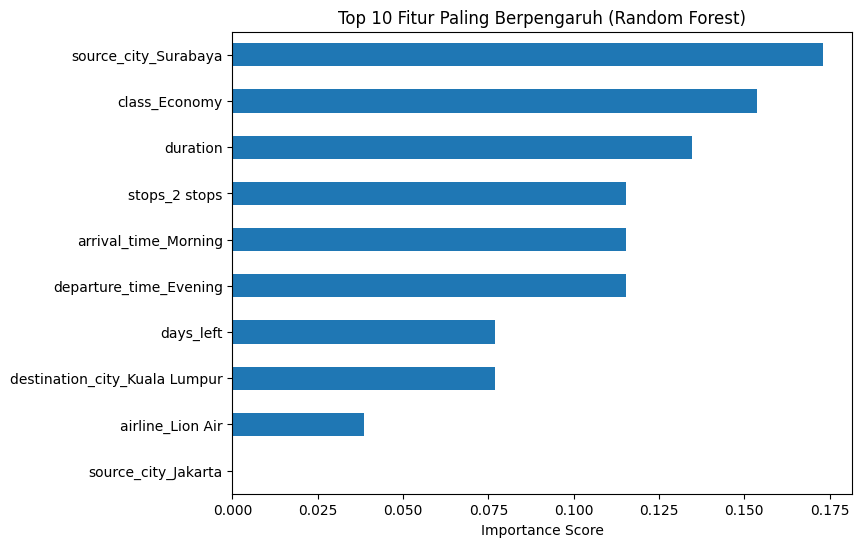

In [ ]:
# Random Forest
importances_rf = models["Random Forest"].feature_importances_
fi_rf = pd.Series(importances_rf, index=X_train.columns).sort_values(ascending=False)
plt.figure(figsize=(8,6))
fi_rf.head(10).plot(kind="barh")
plt.gca().invert_yaxis()
plt.title("Top 10 Fitur Paling Berpengaruh (Random Forest)")
plt.xlabel("Importance Score")
plt.show()

Feature importance (Linear Regression - koefisien):
days_left                     180555.555556
source_city_Surabaya           36111.111111
airline_Lion Air               36111.111111
departure_time_Evening         36111.111111
airline_Garuda                     0.000000
source_city_Jakarta                0.000000
departure_time_Morning             0.000000
destination_city_Singapore         0.000000
stops_non-stop                     0.000000
arrival_time_Night                 0.000000
dtype: float64


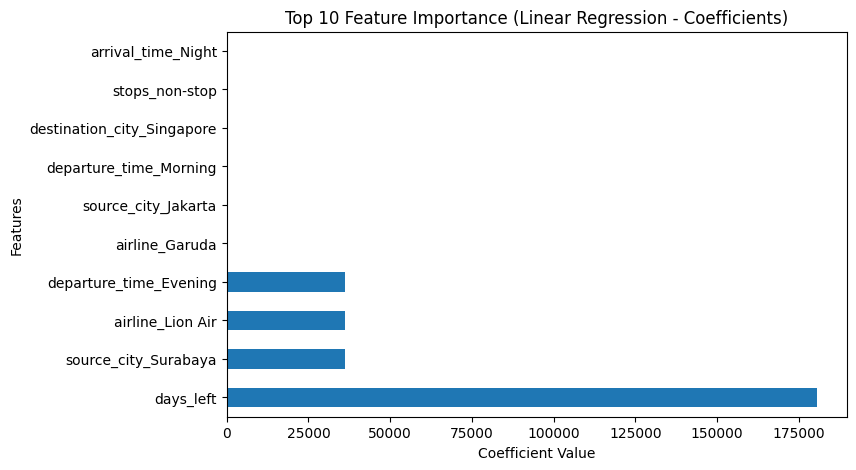

In [ ]:
#Feature Importance: Linear Regression
linreg = models["Linear Regression"]  # pakai model yang sudah fit
coef = pd.Series(linreg.coef_, index=X_train.columns)

# Urutkan koefisien
coef_sorted = coef.sort_values(ascending=False)

print("Feature importance (Linear Regression - koefisien):")
print(coef_sorted.head(10))

# Visualisasi
plt.figure(figsize=(8,5))
coef_sorted.head(10).plot(kind="barh")
plt.title("Top 10 Feature Importance (Linear Regression - Coefficients)")
plt.xlabel("Coefficient Value")
plt.ylabel("Features")
plt.show()
